# Task 2.3: read the memory bit through the buffer

We answer three questions: do the two memory states give different buffer signals, is the drive weak compared with $g_2$, and how long does the response take to settle?

We add $H_Z=\epsilon_Z(a+a^\dagger)$ to the supplied full two-mode model, choose **$\epsilon_Z=0.05g_2$**, and independently evolve $\lvert\pm\alpha\rangle$ with the buffer in vacuum. Both loss channels are retained, $\alpha=2.1$, and $\epsilon_Z/(2\pi)=38.15$ kHz. The drive is twenty times below $g_2$; the sweep below checks proportional response. Preparation errors are excluded.

In [1]:
import sys, json, io
from pathlib import Path
from contextlib import redirect_stdout
from IPython.display import Image, Markdown, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/config.py').is_file() and (p / 'docs/challenge_prompt_v4.md').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
show = lambda name, w=1050: display(Image(filename=str(ROOT / 'figures' / f'{name}.png'), width=w))


In [2]:
RERUN = False
if RERUN:
    from tasks import task_2_3
    with redirect_stdout(io.StringIO()):
        task_2_3.main()
r = json.loads((ROOT / 'results/task_2_3.json').read_text())
p = r['configuration']
s = next(row for row in r['drive_summaries'] if row['drive_ratio'] == p['nominal_drive_ratio'])


## Readout signal: opposite real buffer fields

The real part of $\langle b\rangle$ changes sign with the initial memory state. The drive slightly displaces the memory, and the two-photon coupling makes the buffer response depend on which memory state was occupied. The leading estimate is

$$\langle b\rangle_+\simeq-\frac{\epsilon_Z}{2\alpha g_2},\qquad
\langle b\rangle_-\simeq+\frac{\epsilon_Z}{2\alpha g_2}.$$

Final values below average 3–4 µs. Their real-field separation is the readout signal. The imaginary components are also reported for completeness: they are equal for both memory states and therefore carry no information about which state was prepared. Their memory-loss origin is explained in the report's supporting physics section.

In [3]:
import pandas as pd
branches = pd.DataFrame([
    {'initial memory': '+alpha', 'Re <b>': s['beta_plus'][0], 'Im <b>': s['beta_plus'][1]},
    {'initial memory': '-alpha', 'Re <b>': s['beta_minus'][0], 'Im <b>': s['beta_minus'][1]},
])
display(branches.style.format({'Re <b>': '{:.8f}', 'Im <b>': '{:.8f}'}))
display(Markdown(f"Real separation **{s['real_separation']:.8f}**, versus **{s['leading_separation']:.8f}** predicted; relative difference **{100*s['relative_contrast_error']:.4f}%**."))


,initial memory,Re,Im
0,+alpha,-0.01189484,0.00311514
1,-alpha,0.01189484,0.00311514


Real separation **0.02378968**, versus **0.02380952** predicted; relative difference **-0.0834%**.

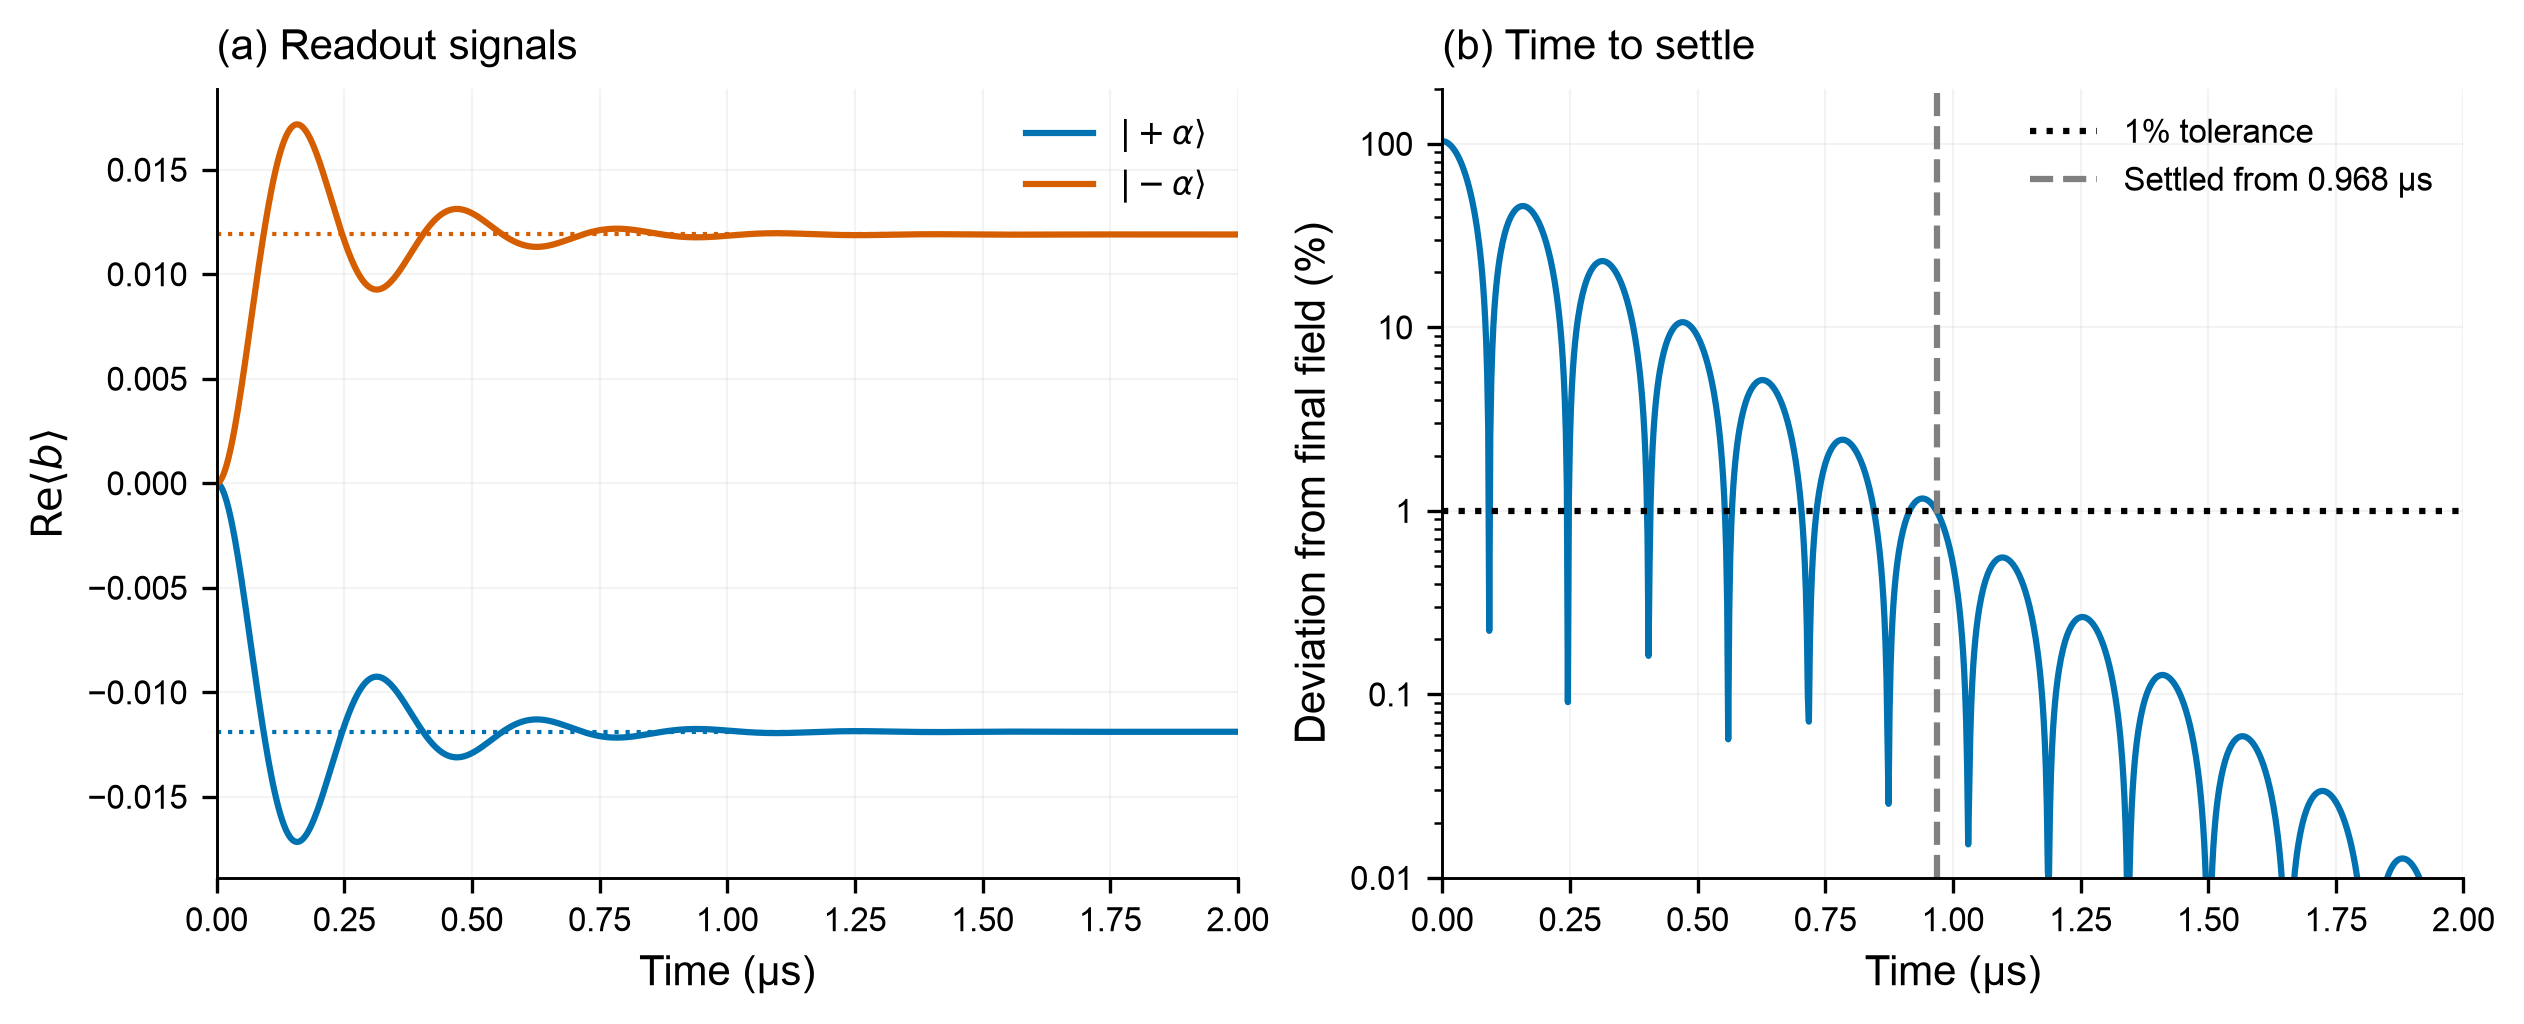

In [4]:
show('task_2_3_readout')

**Readout signals and settling.** Each memory codeword $\lvert\pm\alpha\rangle$ starts with the buffer in vacuum. The full two-mode model includes both loss channels, $\alpha=2.1$, $(N_a,N_b)=(32,12)$ and $\epsilon_Z=0.05g_2$. (a) Real buffer fields; their opposite signs distinguish the two memory states. Dotted lines show the predicted values $\mp\epsilon_Z/(2\alpha g_2)$. The oscillations show that the response does not settle monotonically. (b) The larger deviation of the two complex fields from their respective final values, expressed as a percentage of the predicted field magnitude $\epsilon_Z/(2\alpha g_2)=0.01190476$. Final values are estimated by averaging 3–4 µs. From 0.968 µs onward, both deviations remain below 1% through the end of the 4-µs simulation. The first 2 µs are shown; saved times are 2 ns apart.

## Settling: when does the field stay close to its final value?

The second panel shows the larger deviation of the two complex buffer fields from their final values. Its percentage scale uses the predicted field magnitude $\epsilon_Z/(2\alpha g_2)=0.01190476$ as the reference. Thus **1% means an absolute distance of 0.00011905**. Both real and imaginary components are included.

We call the response settled only when **both fields remain inside that tolerance at every remaining saved time through 4 µs**. Earlier crossings followed by more oscillation do not count. Final values are the 3–4 µs means. A tighter integration with 1-ns saves and an 8-µs run check the result. The main figure shows the first 2 µs to make the oscillation and final crossing easy to see.

In [5]:
display(Markdown(
    f"The first maximum of the signal magnitude occurs at **{s['first_peak_us']:.3f} µs**, with **{100*s['overshoot_fraction']:.1f}%** overshoot. "
    f"The measured peak-spacing period is approximately **{s['ring_period_us']:.3f} µs**. "
    f"Both buffer fields stay inside the 1% tolerance from **{s['settling_time_us']:.3f} µs** through 4 µs; "
    f"the sampled crossing is bracketed by **{s['settling_bracket_us']} µs**."
))


The first maximum of the signal magnitude occurs at **0.158 µs**, with **44.3%** overshoot. The measured peak-spacing period is approximately **0.313 µs**. Both buffer fields stay inside the 1% tolerance from **0.968 µs** through 4 µs; the sampled crossing is bracketed by **[0.966, 0.968] µs**.

## Supporting checks: weak drive and numerical accuracy

These checks establish that the response is approximately proportional to the drive and is stable under numerical refinements. They support the two main results above.

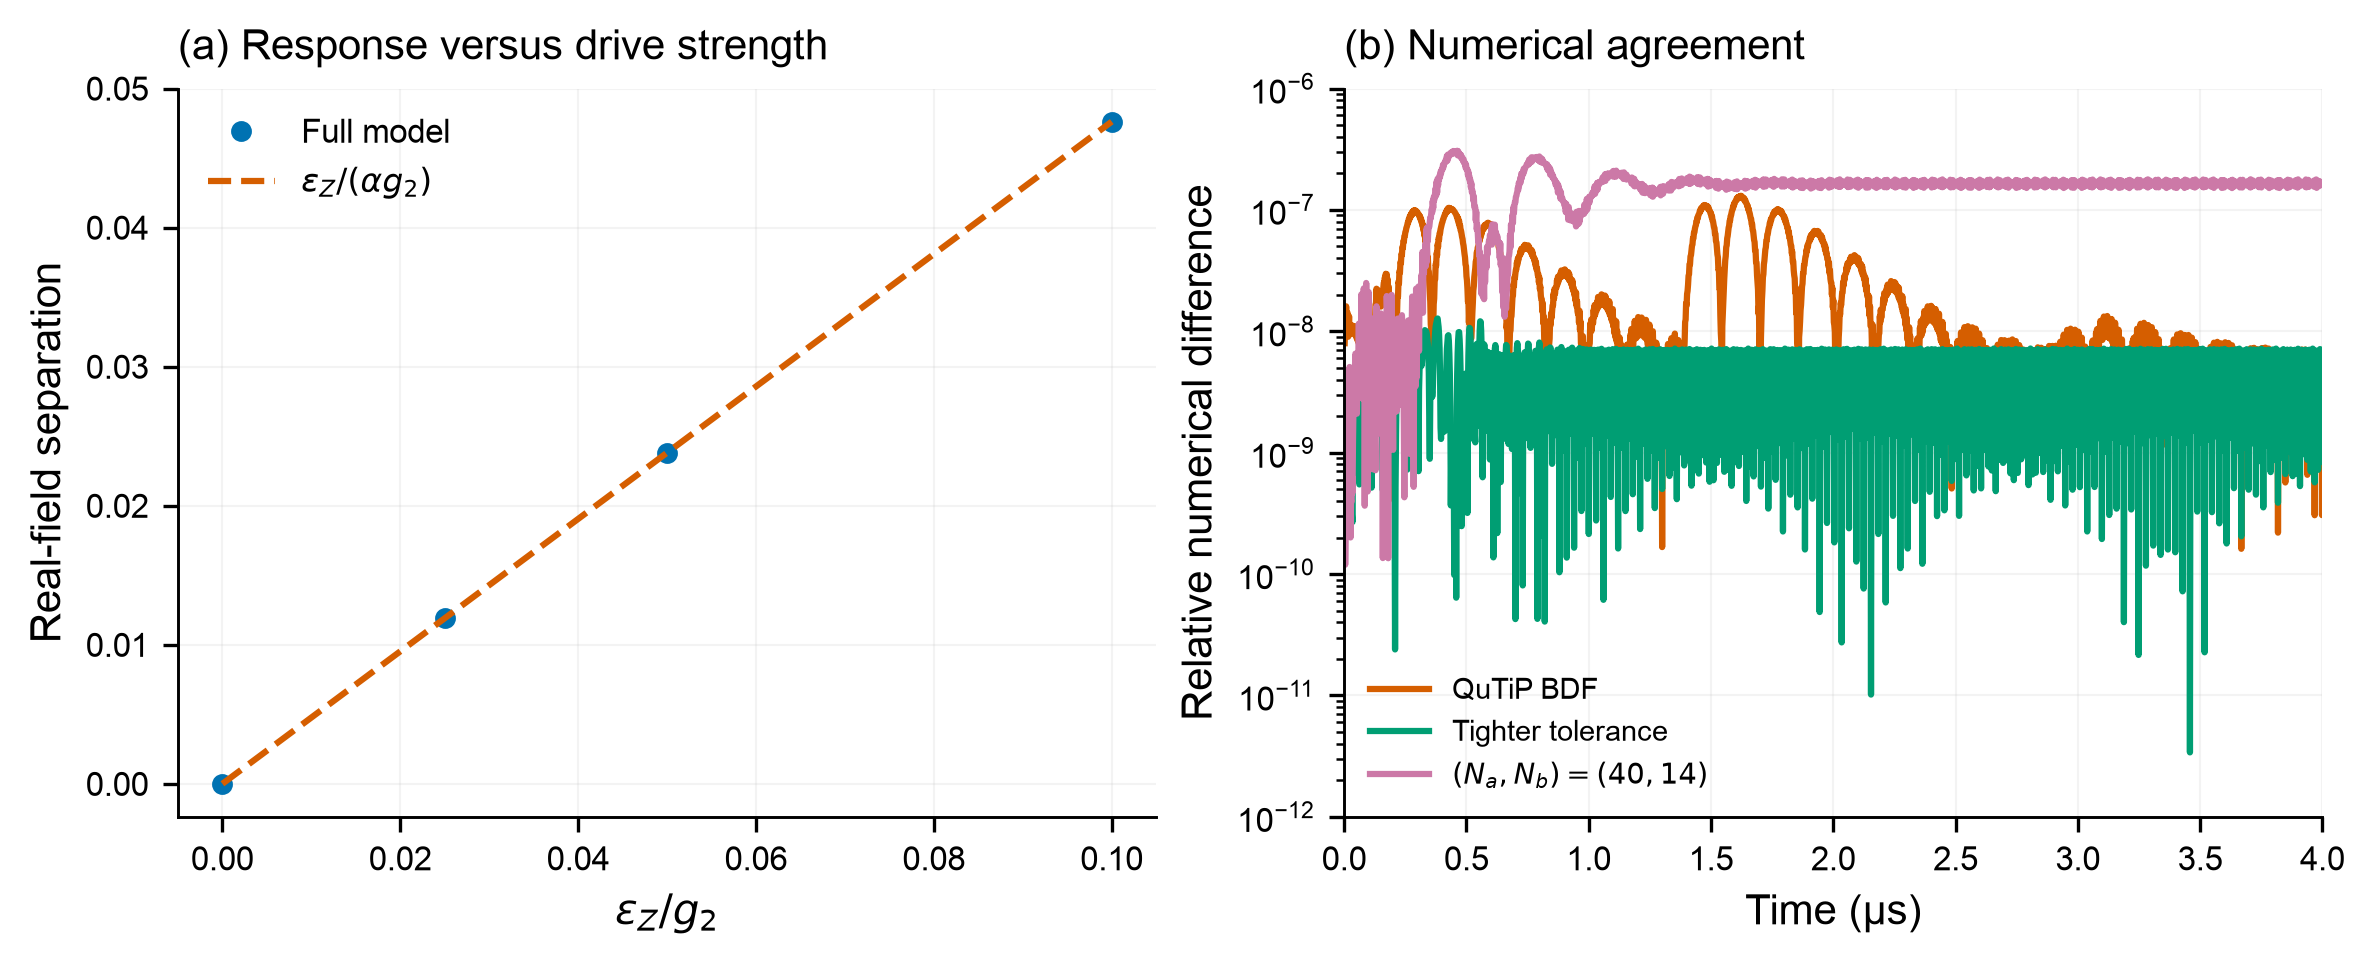

In [6]:
show('task_2_3_validation')

**Supporting checks: drive strength and numerical accuracy.** (a) Real-field separation between the two memory states, averaged over 3–4 µs, versus $\epsilon_Z/g_2$. Dashes show the prediction $\epsilon_Z/(\alpha g_2)$. This checks that the chosen weak drive gives approximately proportional response. (b) Largest complex-field difference between each reference calculation and the production result, over both initial memory states, divided by the nominal predicted field magnitude $\epsilon_Z/(2\alpha g_2)$. References use independent QuTiP BDF and tighter Tsit5 integration at $(32,12)$, and a larger $(40,14)$ cutoff. These check that the reported signal and settling are numerically reliable. Separate memory/buffer cutoff increases and an 8-µs run are recorded in the numerical table.

In [7]:
rows = []
for row in r['drive_summaries']:
    rows.append({'epsilon_Z/g2': row['drive_ratio'], 'real separation': row['real_separation'],
                 'linear prediction': row['leading_separation'],
                 'relative difference (%)': None if row['relative_contrast_error'] is None else 100*row['relative_contrast_error'],
                 'settling time (us)': row['settling_time_us']})
display(pd.DataFrame(rows).style.format(precision=6, na_rep='—'))
cutoffs = pd.DataFrame(r['validation']['cutoffs']).rename(columns={
    'max_complex_field_difference_fraction': 'max field difference / predicted amplitude',
    'relative_contrast_difference': 'relative contrast difference',
    'max_memory_top2': 'max top-2 (a)', 'max_buffer_top': 'max top (b)'})
display(cutoffs.style.format({col: '{:.2e}' for col in cutoffs if col not in ['Na', 'Nb']}))
display(pd.DataFrame(r['validation']['checks'].items(), columns=['check', 'passed']))

v = r['validation']
display(Markdown(
    f"Maximum field differences, divided by the predicted field magnitude: "
    f"**{v['tight_solver_max_field_difference_fraction']:.2e}** for tighter Tsit5 and "
    f"**{v['independent_qutip']['max_field_error_fraction']:.2e}** for independent BDF. "
    f"The change between the 3–4 and 7–8 µs plateaus is "
    f"**{v['extended_8us']['plateau_change_fraction']:.2e}**."
))


,epsilon_Z/g2,real separation,linear prediction,relative difference (%),settling time (us)
0,0.000000,0.000000,0.000000,—,—
1,0.025000,0.011895,0.011905,-0.081015,0.976000
2,0.050000,0.023790,0.023810,-0.083362,0.968000
3,0.100000,0.047575,0.047619,-0.092857,0.966000


,Na,Nb,max field difference / predicted amplitude,relative contrast difference,max top-2 (a),max top (b)
0,24,8,1.02e-05,2.94e-07,7.76e-09,2.93e-08
1,40,12,6.53e-08,5.52e-10,1.74e-09,6.84e-10
2,32,14,3.54e-07,5.86e-09,1.27e-09,1.81e-10
3,40,14,3.07e-07,5.24e-09,1.80e-09,1.88e-10


,check,passed
0,opposite_real_fields,True
1,conjugation_symmetry,True
2,zero_drive_has_no_real_contrast,True
3,weak_drive_linearity,True
4,leading_prediction_within_one_percent,True
5,damped_oscillation_resolved,True
6,settles_before_plateau_window,True
7,late_drift_below_point_one_percent,True
8,cutoff_fields_converged,True
9,boundary_populations_small,True


Maximum field differences, divided by the predicted field magnitude: **1.27e-08** for tighter Tsit5 and **1.31e-07** for independent BDF. The change between the 3–4 and 7–8 µs plateaus is **2.44e-05**.

The checks increase the memory and buffer cutoffs separately and jointly, tighten integration tolerances, refine the output grid, test codeword conjugation symmetry and zero drive, and extend the horizon to 8 µs. Independent QuTiP BDF uses separately constructed operators at the same $(32,12)$ cutoff. Trace and final-state spectrum checks retain signed numerical residuals.

The result files contain trajectories, thresholds, numerical differences, versions and source hashes. Recompute with `python -m tasks.task_2_3`; redraw with `--plot-only`; refresh the analysis with `--reanalyze`. Fresh analysis and reanalysis update the plateau-window metadata, derived flux and checks together. References must cover their full required interval. The notebook loads saved results by default; `RERUN=True` performs the full simulation and validation again.

## What the result establishes

The two memory states give opposite real buffer fields. Their separation agrees with the leading prediction within 0.0834% at the chosen weak drive. The response oscillates, then remains within the stated 1% tolerance from 0.968 µs through 4 µs.

This is the settling time of the **mean field**. It does not specify a single-shot integration time or fidelity; those require a noisy measurement model. The finite observation window also does not establish infinite-time contrast or long-time bit-flip protection. Stronger-drive optimization belongs to Task 2.4.

The [report](../docs/task_2_3_readout.md) gives numerical evidence and optional derivations of the shared imaginary field and approximate oscillation period. The leading estimate follows [Réglade et al., Supplement S8.5](https://arxiv.org/html/2307.06617v2).